In [1]:
# ==============================================================
# CELL 1 — ACGLSR INVERSION ONLY
# ==============================================================

import numpy as np
import time

G = 6.67e-11

# --------------------------------------------------------------
# Forward modelling
# --------------------------------------------------------------

_SIGNS = np.array([(-1)**(i+j+k)
                   for i in range(2)
                   for j in range(2)
                   for k in range(2)], dtype=float)

def _slog(v): 
    return np.log(np.where(np.abs(v) > 1e-30, np.abs(v), 1e-30))

def _satan(y,x):
    return np.arctan2(y, np.where(np.abs(x) > 1e-30, x, 1e-30))

def _r(dx,dy,dz):
    return np.sqrt(dx**2 + dy**2 + dz**2)

def _kernel_tyy(dx, dy, dz): return  _satan(dz*dx, dy*_r(dx,dy,dz))
def _block(fn,obs_x,obs_y,obs_z,px1,px2,py1,py2,pz1,pz2,scale):

    N,M = len(obs_x),len(px1)
    out = np.zeros((N,M))

    cx=[px1,px2]
    cy=[py1,py2]
    cz=[pz1,pz2]

    s=0

    for i in range(2):
        for j in range(2):
            for k in range(2):

                dx=cx[i]-obs_x[:,None]
                dy=cy[j]-obs_y[:,None]
                dz=cz[k]-obs_z[:,None]

                out += _SIGNS[s]*fn(dx,dy,dz)
                s += 1

    return G*out*scale


def build_A(obs_x,obs_y,obs_z,
            px1,px2,py1,py2,pz1,pz2):

    return _block(
        _kernel_tyy,
        obs_x,obs_y,obs_z,
        px1,px2,py1,py2,pz1,pz2,
        1e9
    )
# --------------------------------------------------------------
# Depth weighting
# --------------------------------------------------------------
def build_Wm(pz_c,dx,dy,dz,z0=25,beta=3,alpha_s=0.1):

    w = 1/(z0+pz_c)**(beta/2)
    d = alpha_s*np.sqrt(dx*dy*dz)*w

    return np.maximum(d,1e-12)
# ══════════════════════════════════════════════════════════════════════════════
# ADAPTIVE CGLS REGULARIZATION
# ══════════════════════════════════════════════════════════════════════════════

def acglsr(A, d_obs, wd, wm, m0=None,
           Nmax=50, target_phi=1024,
           delta=0.75,
           m_low=-np.inf, m_high=np.inf,
           verbose=True):

    N, M = A.shape

    # ---------------------------------------------------------
    # Initial model
    # ---------------------------------------------------------
    if m0 is None:
        m0 = np.zeros(M)

    wm_inv = 1.0 / wm

    # ---------------------------------------------------------
    # Weighted system
    # ---------------------------------------------------------
    Aw = (wd[:, None] * A) * wm_inv[None, :]
    dw = wd * (d_obs - A @ m0)

    def Qv(v, mu2):
        return Aw.T @ (Aw @ v) + mu2 * v

    # ---------------------------------------------------------
    # q = Aw^T dw
    # ---------------------------------------------------------
    q = Aw.T @ dw

    # ---------------------------------------------------------
    # Initial mu^2
    # ---------------------------------------------------------
    m_t=np.full(M,5.0)
    dw_t=wd*(d_obs-A@m_t)
    mw_t=wm*(m_t-m0)
    mu2=np.dot(dw_t,dw_t)/(np.dot(mw_t,mw_t)+1e-30)

    if verbose:
        print(
            f"  Initial μ² = {mu2:.4e} "
        )

    # ---------------------------------------------------------
    # Initial model in weighted model space
    # ---------------------------------------------------------
    m_k = np.zeros(M)

    mwk = wm * (m_k - m0)

    # ---------------------------------------------------------
    # Initial residual / search direction
    # ---------------------------------------------------------
    fk = Qv(mwk, mu2) - q

    dk = fk.copy()

    Qdk = Qv(dk, mu2)

    denom_init = np.dot(dk, Qdk)

    tk = (
        np.dot(dk, fk)
        / (denom_init + 1e-30)
    )

    # ---------------------------------------------------------
    # Initial data misfit
    # ---------------------------------------------------------
    resid=wd*(A@m_k-d_obs)
    phi_d=np.dot(resid,resid)

    phi_hist = [phi_d]

    # ---------------------------------------------------------
    # IMPORTANT:
    # Initialize best solution BEFORE using it
    # ---------------------------------------------------------
    best_phi = phi_d
    m_best = m_k.copy()

    if verbose:
        print(
            f"\n  {'Iter':>5}  "
            f"{'phi_d':>14}  "
            f"{'mu2':>12}  "
            f"{'||m||_inf':>10}"
        )

        print("  " + "─" * 52)

        print(
            f"  {'0':>5}  "
            f"{phi_d:>14.6e}  "
            f"{mu2:>12.4e}  "
            f"{np.abs(m_k).max():>10.4f}"
        )

    # =========================================================
    # MAIN ITERATION
    # =========================================================

    for k in range(Nmax):

        # -----------------------------------------------------
        # descent step
        # -----------------------------------------------------
        mwk = mwk - tk * dk

        # -----------------------------------------------------
        # recover physical model
        # -----------------------------------------------------
        m_k = wm_inv * mwk + m0

        # -----------------------------------------------------
        # apply bounds
        # -----------------------------------------------------
        m_k = np.clip(
            m_k,
            m_low,
            m_high
        )
        # -----------------------------------------------------
        # Calculate NEW data misfit
        # -----------------------------------------------------
        resid=wd*(A@m_k-d_obs)
        phi_d=np.dot(resid,resid)
        phi_hist.append(phi_d)

        # -----------------------------------------------------
        # IMPORTANT:
        # Update best model AFTER calculating new phi_d
        # -----------------------------------------------------
        if phi_d < best_phi:

            best_phi = phi_d

            m_best = m_k.copy()

        # -----------------------------------------------------
        # Print iteration
        # -----------------------------------------------------
        if verbose:
            print(
                f"  {k+1:>5}  "
                f"{phi_d:>14.6e}  "
                f"{mu2:>12.4e}  "
                f"{np.abs(m_k).max():>10.4f}"
            )

        # -----------------------------------------------------
        # Stopping criterion
        # -----------------------------------------------------
        if phi_d < target_phi:

            if verbose:
                print(
                    f"\n  ✓ Converged at iteration {k+1}"
                )

            break

        # -----------------------------------------------------
        #  weighted model
        # -----------------------------------------------------
        mwk = wm * (m_k - m0)

        # -----------------------------------------------------
        # Update regularization parameter
        # -----------------------------------------------------
        mu2 = delta**2 * mu2

        # -----------------------------------------------------
        # new residual
        # -----------------------------------------------------
        fk_new = Qv(mwk, mu2) - q

        # -----------------------------------------------------
        # Fletcher-Reeves beta
        # -----------------------------------------------------
        beta_k = (np.dot(fk_new, fk_new) /(np.dot(fk, fk) + 1e-30))

        # -----------------------------------------------------
        # New search direction
        # -----------------------------------------------------
        dk_new = fk_new + beta_k * dk

        # -----------------------------------------------------
        # New step length
        # -----------------------------------------------------
        Qdk = Qv(dk_new, mu2)

        denom = np.dot(dk_new, Qdk)

        tk = (np.dot(dk_new, fk_new)/(denom + 1e-30))

        # -----------------------------------------------------
        # Move to next iteration
        # -----------------------------------------------------
        fk = fk_new

        dk = dk_new

    # =========================================================
    # RETURN BEST MODEL
    # =========================================================

    return m_best, phi_hist

# ==============================================================
# MAIN INVERSION
# ==============================================================

t0 = time.time()
print("=" * 65)
print("  ACGLSR — Double-Prism Test — tyy")
print("  Prism 1: x=[400,600] y=[450,850] z=[150,450]  rho=1000 kg/m³")
print("  Prism 2: x=[900,1100] y=[450,850] z=[50,350]  rho=600 kg/m³")
print("=" * 65)


# Observation grid
sp=50.0

x1d=np.arange(sp/2,1600,sp)
y1d=np.arange(sp/2,1600,sp)

Xo,Yo=np.meshgrid(x1d,y1d)

obs_x=Xo.ravel()
obs_y=Yo.ravel()
obs_z=np.zeros(len(obs_x))

N_obs=len(obs_x)

# Prism grid
nx,ny,nz=32,32,16
dx,dy,dz=50,50,50

xe=np.linspace(0,1600,nx+1)
ye=np.linspace(0,1600,ny+1)
ze=np.linspace(0,800,nz+1)

iz_g,iy_g,ix_g=np.meshgrid(
    np.arange(nz),
    np.arange(ny),
    np.arange(nx),
    indexing="ij"
)

ix_g=ix_g.ravel()
iy_g=iy_g.ravel()
iz_g=iz_g.ravel()

px1=xe[ix_g]
px2=xe[ix_g+1]

py1=ye[iy_g]
py2=ye[iy_g+1]

pz1=ze[iz_g]
pz2=ze[iz_g+1]

pz_c=0.5*(pz1+pz2)

M=len(px1)

cx=0.5*(px1+px2)
cy=0.5*(py1+py2)
cz=0.5*(pz1+pz2)


# --------------------------------------------------------------
# True model
# --------------------------------------------------------------
m_true=np.zeros(M)

mask1=(
    (cx>=400)&(cx<=600)&
    (cy>=450)&(cy<=850)&
    (cz>=150)&(cz<=450)
)

mask2=(
    (cx>=900)&(cx<=1100)&
    (cy>=450)&(cy<=850)&
    (cz>=50)&(cz<=350)
)
m_true[mask1]=1000
m_true[mask2]=600
# --------------------------------------------------------------
# Forward model + noise
# --------------------------------------------------------------
A=build_A(
    obs_x,obs_y,obs_z,
    px1,px2,py1,py2,pz1,pz2
)
d_clean=A@m_true

# ── Add 10% zero-mean Gaussian noise ────────────────────────────────
noise_level = 0.1
rng = np.random.default_rng(123)

std_tyy = np.std(d_clean) # standard deviation of clean data
sigma_tyy = noise_level * std_tyy # standard deviation of noise

noise = rng.normal(0.0, sigma_tyy, size=N_obs)
d_obs = d_clean + noise

print(f"Clean tyy SD       = {std_tyy:.6e} E")
print(f"Noise sigma        = {sigma_tyy:.6e} E")
print(f"Realized noise SD  = {np.std(noise):.6e} E")
print(f"Realized ratio     = {np.std(noise)/std_tyy:.4f}")

wd=np.full(N_obs,1/sigma_tyy)
# --------------------------------------------------------------
# Depth weighting
# --------------------------------------------------------------
wm=build_Wm(
    pz_c,
    dx,dy,dz,
    z0=dz/2,
    beta=3.48,
    alpha_s=0.1
)
# --------------------------------------------------------------
# ACGLSR inversion
# --------------------------------------------------------------
m_pred,phi_hist=acglsr(
    A,d_obs,wd,wm,
    m0=np.zeros(M),
    Nmax=1200,
    target_phi=N_obs,
    delta=0.75,
    m_low=0,
    m_high=2000,
    verbose=True
)
# --------------------------------------------------------------
# Predicted data + statistics
# --------------------------------------------------------------

d_pred=A@m_pred

rms=np.sqrt(np.mean((d_pred-d_obs)**2))

print("\n========================================")
print("INVERSION COMPLETED")
print("========================================")

print(f"RMS error     : {rms:.8f} E")
print(f"Max predicted : {m_pred.max():.4f} kg/m³")
print(f"Min predicted : {m_pred.min():.4f} kg/m³")
print(f"Time          : {time.time()-t0:.1f} s")


# --------------------------------------------------------------
# 3-D models
# --------------------------------------------------------------

sh=(nz,ny,nx)

mt3=m_true.reshape(sh)
mp3=m_pred.reshape(sh)


# Prism statistics

pred_p1=m_pred[mask1]
pred_p2=m_pred[mask2]

print(
    f"Predicted Prism 1: "
    f"mean={pred_p1.mean():.2f}, "
    f"median={np.median(pred_p1):.2f}, "
    f"max={pred_p1.max():.2f}, "
    f"min={pred_p1.min():.2f}"
)

print(
    f"Predicted Prism 2: "
    f"mean={pred_p2.mean():.2f}, "
    f"median={np.median(pred_p2):.2f}, "
    f"max={pred_p2.max():.2f}, "
    f"min={pred_p2.min():.2f}"
)

  ACGLSR — Double-Prism Test — tyy
  Prism 1: x=[400,600] y=[450,850] z=[150,450]  rho=1000 kg/m³
  Prism 2: x=[900,1100] y=[450,850] z=[50,350]  rho=600 kg/m³
Clean tyy SD       = 1.571797e+01 E
Noise sigma        = 1.571797e+00 E
Realized noise SD  = 1.585362e+00 E
Realized ratio     = 0.1009
  Initial μ² = 2.4326e+03 

   Iter           phi_d           mu2   ||m||_inf
  ────────────────────────────────────────────────────
      0    1.082906e+05    2.4326e+03      0.0000
      1    8.138474e+04    2.4326e+03    108.4833
      2    6.651977e+04    1.3683e+03    177.1887
      3    5.255572e+04    7.6969e+02    251.3280
      4    4.034417e+04    4.3295e+02    328.9944
      5    3.115204e+04    2.4353e+02    400.9920
      6    2.505672e+04    1.3699e+02    458.8381
      7    2.117729e+04    7.7056e+01    505.7358
      8    1.845012e+04    4.3344e+01    545.7735
      9    1.611170e+04    2.4381e+01    579.5542
     10    1.384186e+04    1.3714e+01    606.2336
     11    1.176769e+

d_obs =
 [-0.04722429  1.47618886  4.73111282 ...  0.90827171  0.06666501
  3.07805235]

 d_pred =
 [0.50755251 3.432832   4.05184807 ... 0.74310964 0.48030486 0.96856866]

 d_obs maximum = 26.075988775092334
d_pred maximum = 18.687370522170816

 d_obs minimum = -57.55514130693627
d_pred minimum = -54.45255690070816

 d_obs mean = -3.078501022616348
d_pred mean = -3.525636610928938

Zres =
 [[-0.5547768  -1.95664314  0.67926475 ...  0.18164302  0.59186702
   0.06346211]
 [-0.01577769 -1.87376908  0.06589734 ...  0.1693148   1.17359743
  -0.25580507]
 [-1.37040362 -0.14278037 -0.66091746 ... -0.02464094  2.11790652
  -0.22919657]
 ...
 [-1.09056442  0.26468912  0.30840529 ... -0.34891843 -0.6161007
   1.68677983]
 [-1.57779386  0.83140206  1.59151209 ... -0.69048681  0.57045155
   1.39256709]
 [-1.24341603  0.34987497  0.7434733  ...  0.16516207 -0.41363985
   2.10948368]]

Zres maximum = 7.822711605045448
Zres minimum = -4.125907317546577
Zres mean = 0.44713558831258865
RMS residual = 

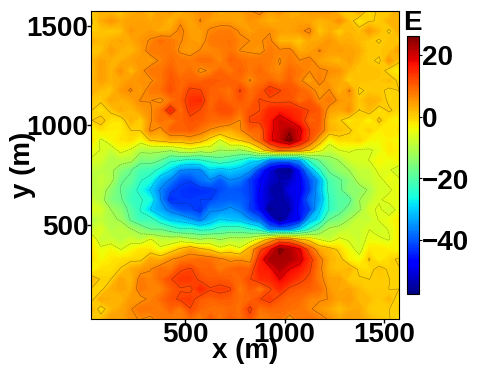

Saved: Fig01_Observed_tyy.png


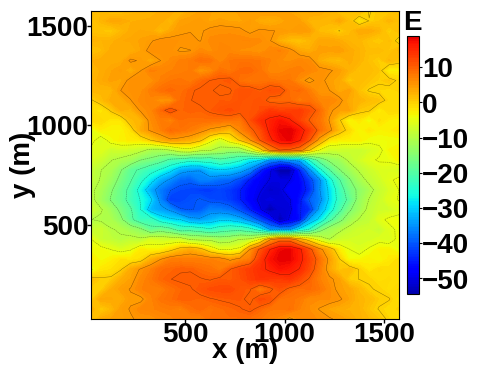

Saved: Fig02_Predicted_tyy.png


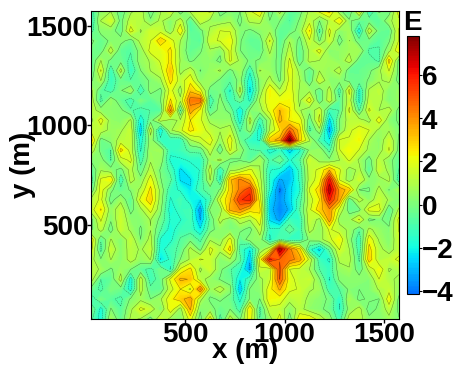

Saved: Fig03_Residual_tyy.png


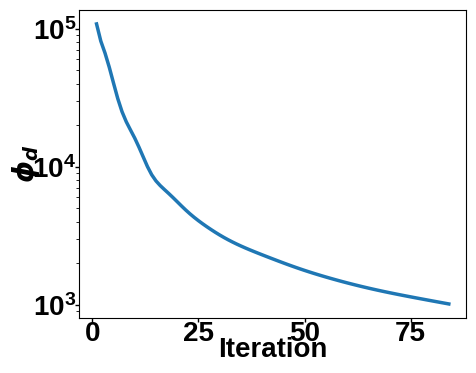

Saved: Fig04_Convergence.png
Convergence data saved: /home/rahul/MTP/INVERSION/ACGLSR_Method/Two_Prism_Model/Two_Prism_Combined_Convergence_all_components/two_P_tyy_Conver_Data.xlsx


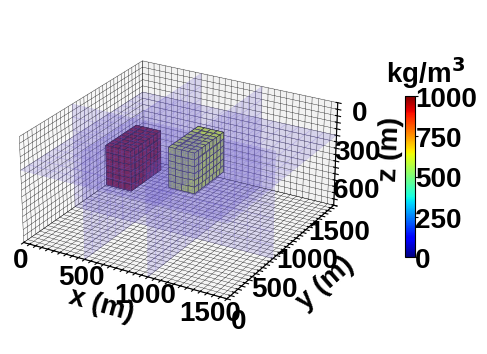

Saved: Fig05_True_3D_Density_Model.png


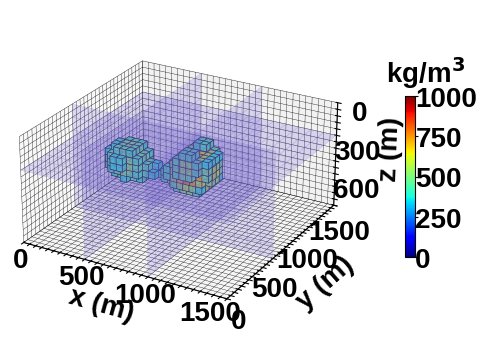

Saved: Fig06_Predicted_3D_Density_Model.png


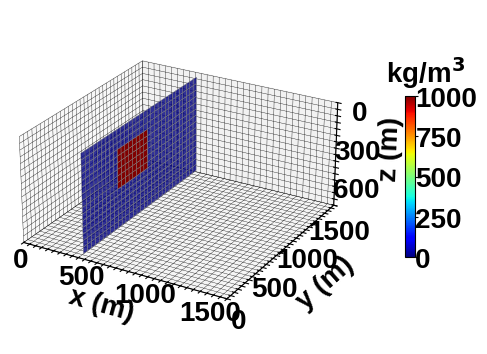

Saved: Fig07_True_YZ_x500.png


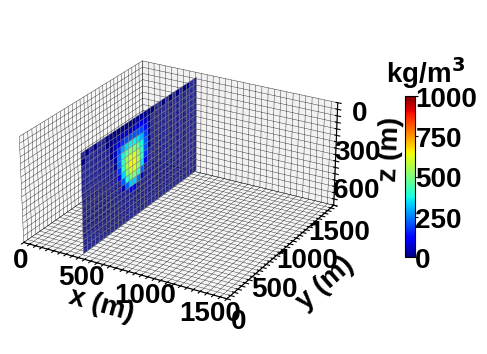

Saved: Fig08_Predicted_YZ_x500.png


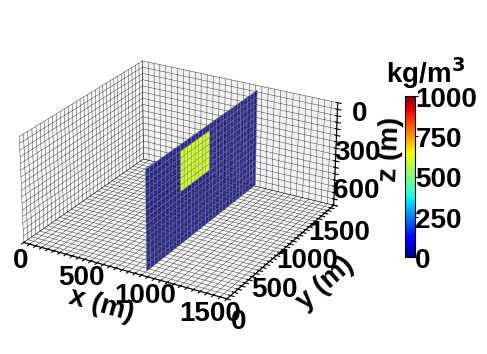

Saved: Fig09_True_YZ_x1000.png


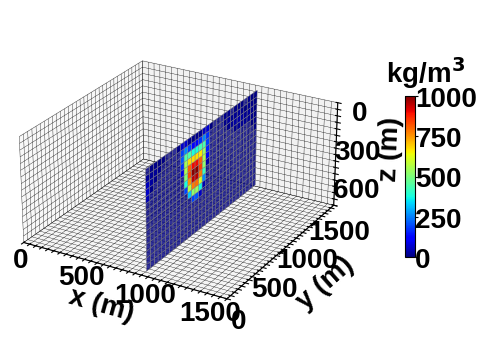

Saved: Fig10_Predicted_YZ_x1000.png


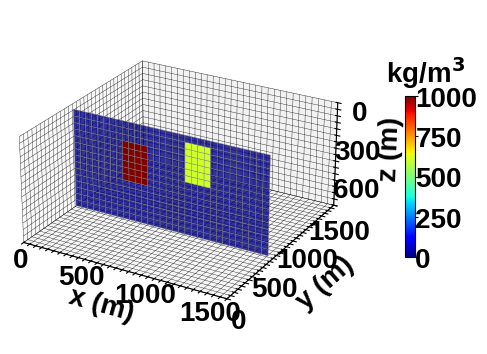

Saved: Fig11_True_XZ_y650.png


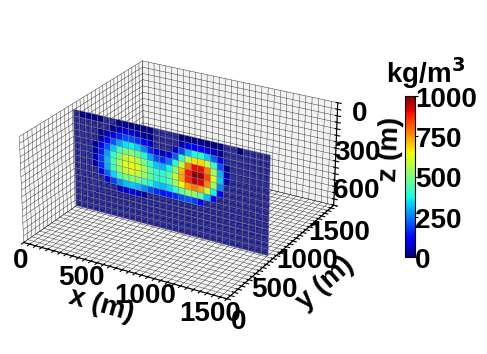

Saved: Fig12_Predicted_XZ_y650.png


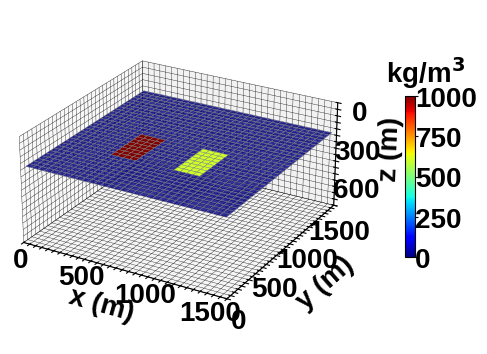

Saved: Fig13_True_XY_z250.png


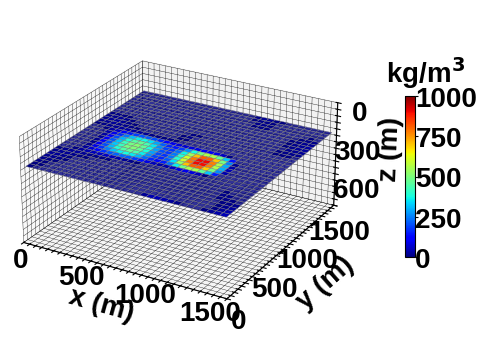

Saved: Fig14_Predicted_XY_z250.png

ALL 14 FIGURES SAVED SUCCESSFULLY
PNG resolution: 600 DPI
NO TITLES ON FIGURES


In [5]:
# =====================================================================
# CELL 2 — PLOT AND SAVE 14 FIGURES SEPARATELY
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, MaxNLocator
from PIL import Image, ImageChops

# -------------------- Global style --------------------
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Liberation Sans","font.size":20,
    "axes.labelsize":20,"axes.titlesize":20,"xtick.labelsize":20,"ytick.labelsize":20,
    "legend.fontsize":20,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})
# -------------------- Axis and colorbar style --------------------
def _style(ax, xl="", yl=""):
    ax.set_facecolor(AX)
    ax.tick_params(axis="both", colors=TC,
                   direction="out", width=1.0, length=3.0,pad=-1.0)
    ax.set_xlabel(xl, color=TC,labelpad=-7.0)
    ax.set_ylabel(yl, color=TC,labelpad=-7.0)
    for sp in ax.spines.values():
        sp.set_edgecolor(TC); sp.set_linewidth(.8)

def _publication_colorbar(cf, ax, fig,title,scientific=False):
    cb = fig.colorbar(cf, ax=ax, shrink=0.84, pad=.02,aspect=21)
    cb.ax.set_title(title,color=TC,y=0.99,x=0.5)
    cb.locator=MaxNLocator(nbins=8,steps=[1,2,2.5,5,10]) # Clean tick spacing
    cb.ax.tick_params(colors=TC, direction="out", width=.8, length=2,pad=0.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
    fmt = ScalarFormatter(useMathText=False)
    fmt.set_scientific(scientific); fmt.set_useOffset(False)
    cb.formatter = fmt; cb.update_ticks()
    return cb

def save_fig(fig,filename,tight=True):
    kw={"dpi":600,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
        
# -------------------- Observation grid --------------------
ng = int(np.sqrt(N_obs))
X, Y = obs_x.reshape(ng,ng), obs_y.reshape(ng,ng)
Zobs, Zpred = d_obs.reshape(ng,ng), d_pred.reshape(ng,ng)
Zres = Zobs - Zpred
vmin, vmax = min(Zobs.min(),Zpred.min()), max(Zobs.max(),Zpred.max())
rmax = np.max(np.abs(Zres))

# -------------------- 2-D tyy plot --------------------
def plot_tyy(data, filename, label, vmin, vmax):
    fig, ax = plt.subplots(figsize=(5,4)); fig.patch.set_facecolor(BG)
    cf = ax.contourf(X,Y,data,levels=150,cmap="jet",vmin=vmin,vmax=vmax)
    ax.contour(X,Y,data,levels=15,colors="k",linewidths=.3,alpha=.5)
    _style(ax,"x (m)","y (m)"); ax.set_aspect("equal")
    _publication_colorbar(cf,ax,fig,"E")
    save_fig(fig,filename)
    
# ============================================================
# Tensor and residual statistics
# ============================================================
# Observed and predicted tensor
print("d_obs =\n", d_obs)
print("\n d_pred =\n", d_pred)

# Maximum values
print("\n d_obs maximum =", np.max(d_obs))
print("d_pred maximum =", np.max(d_pred))

# Minimum values
print("\n d_obs minimum =", np.min(d_obs))
print("d_pred minimum =", np.min(d_pred)) 

# Mean values
print("\n d_obs mean =", np.mean(d_obs))
print("d_pred mean =", np.mean(d_pred))

# Residual tensor: observed - predicted
print("\nZres =\n", Zres)

# Residual statistics
print("\nZres maximum =", np.max(Zres))
print("Zres minimum =", np.min(Zres))
print("Zres mean =", np.mean(Zres))

# RMS residual
rms = np.sqrt(np.mean(Zres**2))
print("RMS residual =", rms)

# -------------------- Figures 1–3 --------------------
plot_tyy(Zobs,"Fig01_Observed_tyy.png","tyy (E)",vmin,vmax)
plot_tyy(Zpred,"Fig02_Predicted_tyy.png","tyy (E)",vmin,vmax)
plot_tyy(Zres,"Fig03_Residual_tyy.png","tyy residual (E)",-rmax,rmax)

# -------------------- Figure 4: convergence --------------------
def plot_convergence(phi,filename):
    fig,ax=plt.subplots(figsize=(5,4))
    ax.semilogy(np.arange(1,len(phi)+1),phi,lw=2.5)
    _style(ax,"Iteration",r"$\phi_d$"); save_fig(fig,filename)

def save_convergence_excel(phi,filename):
    pd.DataFrame({"Iteration":np.arange(1,len(phi)+1),"phi_d":phi}).to_excel(filename,index=False)
    print("Convergence data saved:",filename)

plot_convergence(phi_hist,"Fig04_Convergence.png")

convergence_file="/home/rahul/MTP/INVERSION/ACGLSR_Method/Two_Prism_Model/Two_Prism_Combined_Convergence_all_components/two_P_tyy_Conver_Data.xlsx"
save_convergence_excel(phi_hist,convergence_file)

# -------------------- True prism boundaries --------------------
p1_xlo,p1_xhi,p1_ylo,p1_yhi,p1_zlo,p1_zhi = 400,600,450,850,150,450
p2_xlo,p2_xhi,p2_ylo,p2_yhi,p2_zlo,p2_zhi = 900,1100,450,850,50,350
clim = (0,1000)

# -------------------- Common 3-D settings --------------------
cmap_3d = plt.cm.jet
norm = plt.Normalize(vmin=0,vmax=1000)
X3,Y3,Z3 = np.meshgrid(xe,ye,ze,indexing="ij")

def setup_3d(ax):
    ax.set_xlim(0,1600); ax.set_ylim(0,1600); ax.set_zlim(800,0)
    xg,yg,zg = np.arange(0,1601,50),np.arange(0,1601,50),np.arange(0,801,50)
    ax.set_xticks(xg); ax.set_yticks(yg); ax.set_zticks(zg)
    ax.set_xticklabels([str(v) if v%500==0 else "" for v in xg])
    ax.set_yticklabels([str(v) if v%500==0 else "" for v in yg])
    ax.set_zticklabels([str(v) if v%300==0 else "" for v in zg])
    
    ax.set_xlabel("x (m)",color=TC,labelpad=0.0)
    ax.set_ylabel("y (m)",color=TC,labelpad=5)
    ax.set_zlabel("z (m)",color=TC,labelpad=2.0)
    ax.tick_params(axis="x",colors=TC,direction="out",
                   width=.7,length=3,pad=-5.0)
    ax.tick_params(axis="y",colors=TC,direction="out",
                   width=.7,length=3,pad=-1.0)
    ax.tick_params(axis="z",colors=TC,direction="out",
                   width=.7,length=3,pad=1.0) 
    ax.grid(True)
    for a in [ax.xaxis,ax.yaxis,ax.zaxis]:
        a._axinfo["grid"].update(color="black",linewidth=.25,linestyle="-")
    ax.set_facecolor(AX); ax.set_box_aspect((1600,1600,800))
    ax.view_init(elev=25,azim=-60)

# -------------------- Density boundaries --------------------
def add_density_boundaries(ax,xe,ye,ze,alpha=.2):
    Y,Z=np.meshgrid(ye,ze); X=np.full_like(Y,500,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)
    X=np.full_like(Y,1000,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)
    X,Z=np.meshgrid(xe,ze); Y=np.full_like(X,650,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)
    X,Y=np.meshgrid(xe,ye); Z=np.full_like(X,250,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)

def density_3d_colorbar(fig,ax,cmap,norm):
    sm=mpl.cm.ScalarMappable(cmap=cmap,norm=norm); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=.42,pad=.13,aspect=16)
    cb.ax.set_title(r"kg/m$^3$",color=TC,y=1.03,x=2.0)
    cb.set_ticks(np.arange(0,1001,250))
    cb.ax.tick_params(colors=TC,direction="out",width=.8,length=2,pad=-2.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)

# -------------------- 3-D density model --------------------
def plot_3d_model(arr,filename,threshold):
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")
    filled=arr>threshold; fc=np.zeros((*arr.shape,4))
    fc[filled]=cmap_3d(norm(arr[filled]))
    ax.voxels(X3,Y3,Z3,filled.transpose(2,1,0),
              facecolors=fc.transpose(2,1,0,3),
              edgecolor="black",linewidth=.4,alpha=1,shade=False)
    add_density_boundaries(ax,xe,ye,ze,.2)
    density_3d_colorbar(fig,ax,cmap_3d,norm); setup_3d(ax)
    save_fig(fig,filename)
    
# -------------------- Figures 5–6 --------------------
plot_3d_model(mt3,"Fig05_True_3D_Density_Model.png",.05*1000)
plot_3d_model(mp3,"Fig06_Predicted_3D_Density_Model.png",.40*1000)

# -------------------- Density slice --------------------
def plot_density_slice(model3d,x_slice=None,y_slice=None,z_slice=None,filename=""):
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")
    xc=.5*(xe[:-1]+xe[1:]); yc=.5*(ye[:-1]+ye[1:]); zc=.5*(ze[:-1]+ze[1:])

    if x_slice is not None:
        ix=np.argmin(np.abs(xc-x_slice)); Y,Z=np.meshgrid(yc,zc)
        X=np.full_like(Y,xc[ix]); rho=model3d[:,:,ix]
    elif y_slice is not None:
        iy=np.argmin(np.abs(yc-y_slice)); X,Z=np.meshgrid(xc,zc)
        Y=np.full_like(X,yc[iy]); rho=model3d[:,iy,:]
    elif z_slice is not None:
        iz=np.argmin(np.abs(zc-z_slice)); X,Y=np.meshgrid(xc,yc)
        Z=np.full_like(X,zc[iz]); rho=model3d[iz,:,:]
    else:
        plt.close(fig); return

    fc=cmap_3d(norm(rho)); fc[...,3]=np.where(np.abs(rho)>1e-12,1,.8)
    ax.plot_surface(X,Y,Z,facecolors=fc,rstride=1,cstride=1,
                    linewidth=.3,edgecolor="gray",shade=False,antialiased=True)
    setup_3d(ax); density_3d_colorbar(fig,ax,cmap_3d,norm)
    save_fig(fig,filename)
    
# -------------------- Figures 7–14 --------------------
plot_density_slice(mt3,x_slice=500,filename="Fig07_True_YZ_x500.png")
plot_density_slice(mp3,x_slice=500,filename="Fig08_Predicted_YZ_x500.png")
plot_density_slice(mt3,x_slice=1000,filename="Fig09_True_YZ_x1000.png")
plot_density_slice(mp3,x_slice=1000,filename="Fig10_Predicted_YZ_x1000.png")
plot_density_slice(mt3,y_slice=650,filename="Fig11_True_XZ_y650.png")
plot_density_slice(mp3,y_slice=650,filename="Fig12_Predicted_XZ_y650.png")
plot_density_slice(mt3,z_slice=250,filename="Fig13_True_XY_z250.png")
plot_density_slice(mp3,z_slice=250,filename="Fig14_Predicted_XY_z250.png")

# =====================================================================
# COMPLETE
# =====================================================================
print("\n==============================================")
print("ALL 14 FIGURES SAVED SUCCESSFULLY")
print("PNG resolution: 600 DPI")
print("NO TITLES ON FIGURES")
print("==============================================")

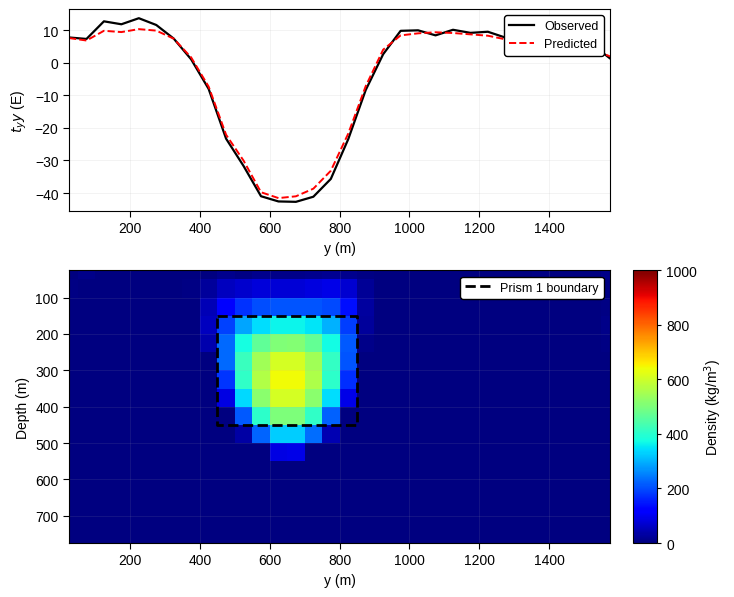

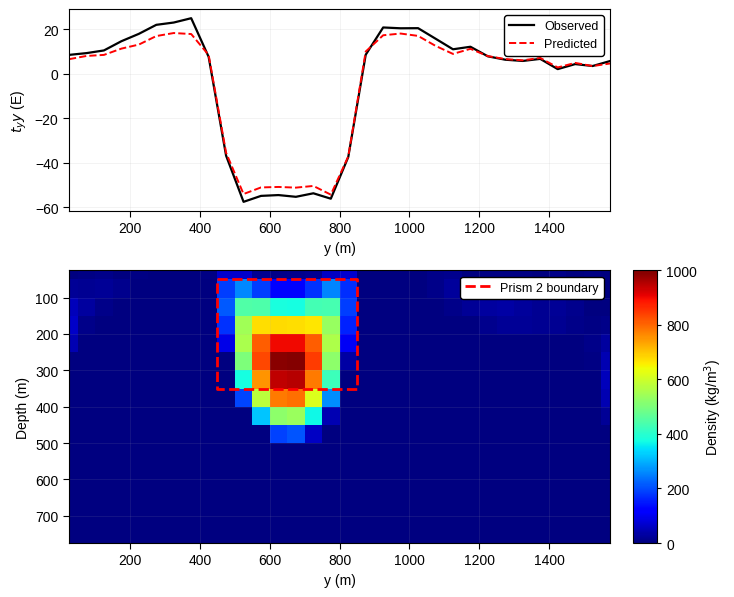

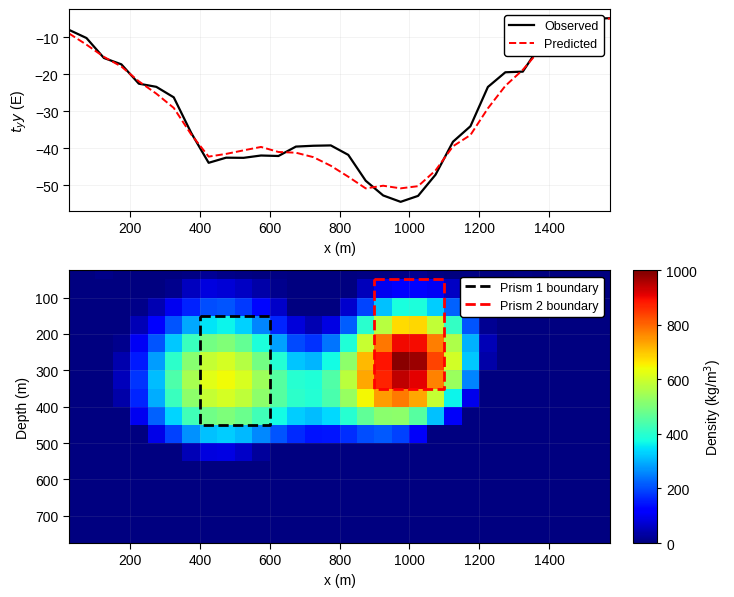

In [3]:
# =====================================================================
# 14–16. TWO-PRISM tyy PROFILES + DENSITY SECTIONS
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl

# =====================================================================
# TRUE TWO-PRISM BOUNDS
# =====================================================================
p1_xlo,p1_xhi,p1_ylo,p1_yhi,p1_zlo,p1_zhi=400.,600.,450.,850.,150.,450.
p2_xlo,p2_xhi,p2_ylo,p2_yhi,p2_zlo,p2_zhi=900.,1100.,450.,850.,50.,350.

# =====================================================================
# PROFILE + DENSITY-SECTION FUNCTION
# =====================================================================
def plot_profile_density_section(direction,coordinate,filename):

    direction=direction.upper()
    xc,yc,zc=[(a[:-1]+a[1:])/2 for a in (xe,ye,ze)]

    if direction=="EW":
        i=np.argmin(np.abs(Y[:,0]-coordinate))
        profile,obs,pred=X[i],Zobs[i],Zpred[i]
        pd.DataFrame({"x (m)":profile,"Observed tyy (E)":obs,
                      "Predicted tyy (E)":pred}).to_excel(
                      f"XZ_tyy_Profile_y{int(coordinate)}.xlsx",index=False)
        j=np.argmin(np.abs(yc-coordinate))
        section=mp3[:,j,:]
        Xsec,Zsec=np.meshgrid(xc,zc)
        xlabel="x (m)"
        b1=[p1_xlo,p1_xhi,p1_xhi,p1_xlo,p1_xlo]
        b2=[p2_xlo,p2_xhi,p2_xhi,p2_xlo,p2_xlo]
        show1=p1_ylo<=coordinate<=p1_yhi
        show2=p2_ylo<=coordinate<=p2_yhi

    elif direction=="NS":
        i=np.argmin(np.abs(X[0]-coordinate))
        profile,obs,pred=Y[:,i],Zobs[:,i],Zpred[:,i]
        pd.DataFrame({"y (m)":profile,"Observed tyy (E)":obs,
                      "Predicted tyy (E)":pred}).to_excel(
                      f"YZ_tyy_Profile_x{int(coordinate)}.xlsx",index=False)
        j=np.argmin(np.abs(xc-coordinate))
        section=mp3[:,:,j]
        Xsec,Zsec=np.meshgrid(yc,zc)
        xlabel="y (m)"
        b1=[p1_ylo,p1_yhi,p1_yhi,p1_ylo,p1_ylo]
        b2=[p2_ylo,p2_yhi,p2_yhi,p2_ylo,p2_ylo]
        show1=p1_xlo<=coordinate<=p1_xhi
        show2=p2_xlo<=coordinate<=p2_xhi

    else:
        raise ValueError("direction must be 'EW' or 'NS'")

    bz1=[p1_zlo,p1_zlo,p1_zhi,p1_zhi,p1_zlo]
    bz2=[p2_zlo,p2_zlo,p2_zhi,p2_zhi,p2_zlo]

    # --- Figure layout ---
    fig=plt.figure(figsize=(7,6))
    gs=fig.add_gridspec(2,2,height_ratios=[1,1.35],
                        width_ratios=[1,.045],hspace=.25,wspace=.08)
    ax1=fig.add_subplot(gs[0,0]); ax2=fig.add_subplot(gs[1,0])
    cax=fig.add_subplot(gs[1,1]); fig.patch.set_facecolor(BG)

    # --- tyy profile ---
    ax1.plot(profile,obs,"k-",lw=1.6,label="Observed")
    ax1.plot(profile,pred,"r--",lw=1.4,label="Predicted")
    _style(ax1,xlabel,r"$t_yy$ (E)")
    ax1.set_xlim(profile.min(),profile.max())
    ax1.tick_params(axis="both",labelsize=10)
    ax1.grid(True,lw=.4,alpha=.25)
    ax1.legend(loc="upper right",frameon=True,framealpha=1,
               edgecolor="black",fontsize=9)

    # --- Density section ---
    pcm=ax2.pcolormesh(Xsec,Zsec,section,cmap="jet",
                       vmin=0,vmax=1000,shading="auto")
    ax2.set_xlim(profile.min(),profile.max())
    ax2.set_ylim(zc.max(),zc.min())
    _style(ax2,xlabel,"Depth (m)")
    ax2.tick_params(axis="both",labelsize=10)
    ax2.grid(True,lw=.4,alpha=.20)

    # --- True prism boundaries ---
    if show1:
        ax2.plot(b1,bz1,"k--",lw=2,zorder=10,label="Prism 1 boundary")
    if show2:
        ax2.plot(b2,bz2,"r--",lw=2,zorder=10,label="Prism 2 boundary")

    h,l=ax2.get_legend_handles_labels()
    if h:
        ax2.legend(h,l,loc="upper right",fontsize=9,
                   frameon=True,framealpha=1,edgecolor="black")

    # --- Colorbar ---
    cb=fig.colorbar(pcm,cax=cax)
    cb.set_label(r"Density (kg/m$^3$)",fontsize=10,color=TC)
    cb.ax.tick_params(labelsize=10,colors=TC,direction="out",
                      width=.8,length=3)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)

    # --- Save ---
    fig.subplots_adjust(left=.10,right=.94,top=.97,bottom=.08)
    fig.savefig(filename,dpi=600,bbox_inches="tight",
                pad_inches=.02,facecolor=BG)
    plt.show(); plt.close(fig)


# =====================================================================
# FIGURE 15 — YZ AT x = 500 m
# =====================================================================

plot_profile_density_section("NS",500,
                             "Fig15_YZ_Profile_Density_Section_x500.png")

# =====================================================================
# FIGURE 16 — YZ AT x = 1000 m
# =====================================================================

plot_profile_density_section("NS",1000,
                             "Fig16_YZ_Profile_Density_Section_x1000.png")

# =====================================================================
# FIGURE 17 — XZ AT y = 650 m
# =====================================================================

plot_profile_density_section("EW",650,
                             "Fig17_XZ_Profile_Density_Section_y650.png")